# Análisis exploratorio (EDA) de los rodamientos NASA IMS

**Para qué.** Antes de aplicar cartas de control y reglas de Nelson hay que conocer los datos: si están completos,
cómo se comporta cada indicador, qué cambia antes de la falla y si se cumplen los supuestos que necesitan las
cartas (proceso estable, puntos independientes y aproximadamente normales).

**Datos.** 3 ensayos llevados hasta la falla, 4 rodamientos en un mismo eje a 2000 rpm. Cada archivo es 1 s de
vibración a 20 kHz, tomado cada 10 min. De cada archivo se calcularon 13 indicadores por canal
(`scripts/ims_features.py`); en el ensayo 1 hay 2 canales por rodamiento y aquí se promedian.

| Ensayo | Rodamiento que falla | Tipo de falla |
| --- | --- | --- |
| 1 | B3 y B4 | Pista interna (B3), elemento rodante (B4) |
| 2 | B1 | Pista externa |
| 3 | B3 | Pista externa |

El **baseline** de cada ensayo (24 h estables elegidas por el CV, fase 2) se marca en las figuras.

In [1]:
import os
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.colors import LinearSegmentedColormap
from matplotlib.lines import Line2D
from scipy import signal, stats

warnings.filterwarnings("ignore", category=RuntimeWarning)
pd.set_option("display.width", 200, "display.max_columns", 30)

RAIZ = r"C:\Users\mcaro\Downloads\IMS\IMS"
CARPETAS = {1: os.path.join(RAIZ, "1st_test", "1st_test"),
            2: os.path.join(RAIZ, "2nd_test", "2nd_test"),
            3: os.path.join(RAIZ, "3rd_test", "4th_test", "txt")}
ARCHIVOS = {1: "ims_features.csv", 2: "ims2_features.csv", 3: "ims3_features.csv"}
FALLAN = {1: ["B3", "B4"], 2: ["B1"], 3: ["B3"]}
RODS = ["B1", "B2", "B3", "B4"]
FS = 20_000
BPFO, BPFI = 236.4, 296.9
HUECO = pd.Timedelta("30min")

FEATS = ["rms", "pico", "cresta", "kurt", "skew", "banda_0_1k", "banda_1_2k", "banda_2_5k",
         "banda_5_10k", "env_BPFO", "env_BPFI", "env_BSF", "env_FTF"]
NOMBRES = {"rms": "RMS", "pico": "Pico", "cresta": "Factor de cresta", "kurt": "Curtosis",
           "skew": "Asimetría", "banda_0_1k": "Energía 0–1 kHz", "banda_1_2k": "Energía 1–2,5 kHz",
           "banda_2_5k": "Energía 2,5–5 kHz", "banda_5_10k": "Energía 5–10 kHz",
           "env_BPFO": "Envolvente BPFO", "env_BPFI": "Envolvente BPFI", "env_BSF": "Envolvente BSF",
           "env_FTF": "Envolvente FTF"}

base_tab = pd.read_csv("baseline_ims.csv", parse_dates=["base_ini", "base_fin"])
crudos, datos, muertos = {}, {}, {}
for e, ruta in ARCHIVOS.items():
    crudo = pd.read_csv(ruta, parse_dates=["Timestamp"])
    crudos[e] = crudo
    # Archivos con todos los canales casi en cero: la máquina ya estaba detenida. Se excluyen del análisis.
    rms = crudo.filter(regex=r"_rms$")
    muerto = (rms < 0.2 * rms.median()).all(axis=1)
    muertos[e] = crudo.loc[muerto, "Timestamp"].tolist()
    crudo = crudo[~muerto].reset_index(drop=True)
    df = pd.DataFrame({"Timestamp": crudo["Timestamp"]})
    for b in RODS:
        for f in FEATS:
            df[f"{b}_{f}"] = crudo.filter(regex=rf"^{b}_Ch\d_{f}$").mean(axis=1)
    df["horas_al_fin"] = (df["Timestamp"].iloc[-1] - df["Timestamp"]).dt.total_seconds() / 3600
    df["tramo"] = (df["Timestamp"].diff() > HUECO).cumsum()
    ini, fin = base_tab.loc[base_tab["ensayo"] == e, ["base_ini", "base_fin"]].iloc[0]
    df["fase"] = np.where(df["Timestamp"].between(ini, fin), "base",
                          np.where(df["Timestamp"] > fin, "monitoreo", "previo"))
    datos[e] = df
print({e: d.shape for e, d in datos.items()})
print("Archivos con señal muerta (excluidos):", {e: [str(t) for t in m] for e, m in muertos.items()})

{1: (2156, 56), 2: (982, 56), 3: (6323, 56)}
Archivos con señal muerta (excluidos): {1: [], 2: ['2004-02-19 06:12:39', '2004-02-19 06:22:39'], 3: ['2004-04-18 02:42:55']}


In [2]:
# Estilo: marcas delgadas, ejes y rejilla discretos; gris para los sanos y un color por rodamiento que falla
AZUL, NARANJA, ROJO = "#2a78d6", "#eb6834", "#e34948"
TINTA, TINTA2, TENUE, REJILLA, FONDO, GRIS = "#0b0b0b", "#52514e", "#898781", "#e1e0d9", "#fcfcfb", "#a9a8a2"
plt.rcParams.update({
    "figure.facecolor": FONDO, "axes.facecolor": FONDO, "savefig.facecolor": FONDO,
    "axes.edgecolor": TENUE, "axes.labelcolor": TINTA2, "axes.titlecolor": TINTA,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "axes.grid.axis": "y", "grid.color": REJILLA, "grid.linewidth": 0.6,
    "xtick.color": TENUE, "ytick.color": TENUE, "xtick.labelcolor": TINTA2, "ytick.labelcolor": TINTA2,
    "font.size": 10, "axes.titlesize": 11, "axes.titleweight": "bold", "legend.frameon": False,
    "figure.dpi": 110,
})


def color_rod(e, b):
    if b not in FALLAN[e]:
        return GRIS
    return [NARANJA, AZUL][FALLAN[e].index(b)]


def con_cortes(df, y):
    # Inserta NaN entre tramos para que la línea no una los huecos de registro
    x = -df["horas_al_fin"].to_numpy(dtype=float)
    y = np.asarray(y, dtype=float).copy()
    corte = np.r_[False, np.diff(df["tramo"].to_numpy()) > 0]
    return np.insert(x, np.where(corte)[0], np.nan), np.insert(y, np.where(corte)[0], np.nan)

### Términos clave en palabras simples

| Término | Qué es |
| --- | --- |
| Rodamiento | Pieza que permite que el eje gire con poca fricción: dos anillos (pistas) con bolas o rodillos entre ellos. |
| Acelerómetro | Sensor pegado a la carcasa del rodamiento que mide su vibración 20 000 veces por segundo. Se mide en g (aceleración de la gravedad). |
| RMS | La cantidad promedio de vibración en un segundo. Si sube, el rodamiento vibra más. |
| Pico y factor de cresta | El pico es el golpe más fuerte del segundo; el factor de cresta es el pico dividido por el RMS (qué tan sobresaliente es ese golpe). |
| Curtosis | Mide si la vibración tiene golpes aislados. Una grieta pequeña produce un golpecito cada vez que pasa una bola, y la curtosis sube. |
| Asimetría | Si la vibración se carga más hacia un lado (positivo o negativo). En una máquina sana es cercana a 0. |
| Energía por bandas | Qué porcentaje de la vibración está en sonidos graves (0–1 kHz) o agudos (5–10 kHz). |
| Envolvente y frecuencia de defecto | Cada parte dañada golpea a un ritmo fijo: BPFO (pista externa, ~236 golpes por segundo), BPFI (pista interna), BSF (bolas) y FTF (jaula). La envolvente busca ese ritmo. |
| Baseline (línea base) | 24 horas en que el rodamiento está sano y estable; se usa como referencia de lo normal. |
| σ (sigma) | Cuánto varía normalmente la señal alrededor de su promedio. "Cambió 11σ" quiere decir que se movió 11 veces más de lo normal. |
| Coeficiente de variación (CV) | σ dividida por el promedio, en porcentaje. Un CV de 1 % es una señal muy estable. |
| Correlación de Spearman (ρ) | Mide si dos cosas suben y bajan juntas, de −1 a 1. Cerca de 1: se mueven igual. |
| Autocorrelación | Qué tanto se parece un punto al anterior. Si es alta, los puntos no son independientes. |
| Prueba de Shapiro-Wilk | Revisa si los datos tienen forma de campana (distribución normal). Un p menor que 0,05 indica que no. |
| Valor atípico (vallas de Tukey) | Un valor mucho más alto o más bajo que la mayoría; aquí, fuera del rango normal del baseline. |
| Carta de control | Gráfica de la señal en el tiempo con límites calculados en el baseline; si la señal se sale o forma ciertos patrones, suena una alarma. |

## 1. Estructura y calidad de los datos

Una fila = un archivo (1 s de vibración) de un ensayo; la clave es el `Timestamp`. Revisamos tamaño, cobertura en el
tiempo, huecos de registro, duplicados, faltantes y si los archivos crudos tienen el mismo tamaño.

Los últimos archivos de los ensayos 2 y 3 tienen **todos los canales casi en cero** (~0,001 g): la máquina ya estaba
detenida. Se excluyen del resto del análisis y "horas antes del fin" se mide desde el último archivo con señal.

In [3]:
filas = []
for e, df in datos.items():
    t, dt = df["Timestamp"], df["Timestamp"].diff()
    nombres = sorted(os.listdir(CARPETAS[e]))
    kb = np.array([os.path.getsize(os.path.join(CARPETAS[e], a)) for a in nombres]) / 1024
    muestra = pd.read_csv(os.path.join(CARPETAS[e], nombres[0]), sep="\t", header=None)
    filas.append({
        "Ensayo": e, "Archivos": len(df) + len(muertos[e]), "Canales": muestra.shape[1], "Muestras por archivo": muestra.shape[0],
        "Inicio": t.min(), "Fin": t.max(),
        "Horas de reloj": round((t.max() - t.min()).total_seconds() / 3600),
        "Horas con registro": round(dt[dt <= HUECO].sum().total_seconds() / 3600),
        "Huecos > 30 min": int((dt > HUECO).sum()),
        "Intervalo típico": dt.median(),
        "Timestamps duplicados": int(t.duplicated().sum()),
        "Valores faltantes": int(crudos[e].isna().sum().sum()),
        "Archivos con señal muerta": len(muertos[e]),
        "Tamaño archivo (KB)": f"{kb.min():.0f}–{kb.max():.0f}",
    })
estructura = pd.DataFrame(filas).set_index("Ensayo")
estructura.T

Ensayo,1,2,3
Archivos,2156,984,6324
Canales,8,4,4
Muestras por archivo,20480,20480,20480
Inicio,2003-10-22 12:06:24,2004-02-12 10:32:39,2004-03-04 09:27:46
Fin,2003-11-25 23:39:56,2004-02-19 06:02:39,2004-04-18 02:32:55
Horas de reloj,828,164,1073
Horas con registro,341,164,1053
Huecos > 30 min,24,0,4
Intervalo típico,0 days 00:10:00,0 days 00:10:00,0 days 00:10:00
Timestamps duplicados,0,0,0


In [4]:
# Intervalos entre archivos: el muestreo no es siempre de 10 min
for e, df in datos.items():
    dt = df["Timestamp"].diff().dropna().dt.total_seconds().div(60).round()
    print(f"Ensayo {e}:", dt.value_counts().head(4).to_dict(), "(minutos: archivos)")

Ensayo 1: {10.0: 1962, 5.0: 148, 9.0: 5, 6.0: 4} (minutos: archivos)
Ensayo 2: {10.0: 981} (minutos: archivos)
Ensayo 3: {10.0: 6314, 5.0: 2, 270.0: 1, 2.0: 1} (minutos: archivos)


**Chequeos de consistencia.** Si algún número rompiera estas reglas, habría un error en los datos o en el código. Reglas físicas que deben cumplirse: RMS y pico positivos, factor de cresta ≥ 1,
fracciones de energía por banda entre 0 y 1 que suman ~1 (las 4 bandas cubren 0–10 kHz), envolventes positivas.

In [5]:
filas = []
for e, crudo in crudos.items():
    num = crudo.drop(columns="Timestamp")
    bandas = [c for c in num if "_banda_" in c]
    suma = sum(num[c] for c in bandas if c.startswith("B1_Ch1_"))
    filas.append({
        "Ensayo": e,
        "RMS ≤ 0": int((num.filter(like="_rms") <= 0).sum().sum()),
        "Factor de cresta < 1": int((num.filter(like="_cresta") < 1).sum().sum()),
        "Banda fuera de [0, 1]": int(((num[bandas] < 0) | (num[bandas] > 1)).sum().sum()),
        "Máx. |suma bandas − 1| (B1)": f"{(suma - 1).abs().max():.1e}",
        "Envolvente ≤ 0": int((num.filter(like="_env_") <= 0).sum().sum()),
        "Valores infinitos": int(np.isinf(num.to_numpy()).sum()),
    })
pd.DataFrame(filas).set_index("Ensayo")

,RMS ≤ 0,Factor de cresta < 1,"Banda fuera de [0, 1]",Máx. |suma bandas − 1| (B1),Envolvente ≤ 0,Valores infinitos
Ensayo,,,,,,
1,0,0,0,2.4e-04,0,0
2,0,0,0,7.5e-05,0,0
3,0,0,0,1.4e-04,0,0


**Coherencia entre los dos canales del ensayo 1.** Cada rodamiento tiene dos acelerómetros (horizontal y vertical).
Si miden lo mismo, promediarlos es razonable.

In [6]:
crudo = crudos[1]
tabla = pd.DataFrame({
    NOMBRES[f]: {b: crudo[f"{b}_Ch1_{f}"].corr(crudo[f"{b}_Ch2_{f}"], method="spearman") for b in RODS}
    for f in ["rms", "kurt", "pico", "env_BPFI"]})
tabla.index.name = "Rodamiento (ensayo 1)"
tabla.round(2)

,RMS,Curtosis,Pico,Envolvente BPFI
Rodamiento (ensayo 1),,,,
B1,0.89,0.39,0.15,0.06
B2,0.80,0.40,0.16,0.07
B3,0.91,0.48,0.60,0.17
B4,0.96,0.78,0.78,0.46


**Qué quiere decir.** Los datos están completos y son coherentes físicamente. Los únicos problemas son los 3 archivos
del final con la máquina apagada (ya excluidos) y los huecos del ensayo 1, donde la prueba se detuvo y se reanudó días
después. Esos reinicios cambian un poco el nivel de vibración y pueden hacer sonar alarmas aunque no haya falla.

## 2. Perfil de los indicadores

Cada indicador en el baseline (estado sano) y cuánto se aleja en las **últimas 24 h** antes del fin, en unidades de
la desviación estándar del baseline. Se toma la mediana de los 4 rodamientos que fallan y de los 8 sanos. Un buen
indicador de falla se aleja mucho en los que fallan y poco en los sanos.

In [7]:
filas = []
for f in FEATS:
    z_falla, z_sano, cvs, medianas = [], [], [], []
    for e, df in datos.items():
        base, fin = df["fase"] == "base", df["horas_al_fin"] <= 24
        for b in RODS:
            s = df[f"{b}_{f}"]
            z = (s[fin].median() - s[base].median()) / s[base].std()
            (z_falla if b in FALLAN[e] else z_sano).append(z)
            cvs.append(100 * s[base].std() / s[base].mean())
            medianas.append(s[base].median())
    positiva = f not in ("kurt", "skew")  # el CV no tiene sentido si la media puede ser ~0
    filas.append({"Indicador": NOMBRES[f],
                  "Mediana en baseline": np.median(medianas),
                  "CV en baseline (%)": np.median(cvs) if positiva else np.nan,
                  "Cambio final, fallan (σ)": np.median(z_falla),
                  "Cambio final, sanos (σ)": np.median(z_sano)})
perfil = pd.DataFrame(filas).set_index("Indicador")
perfil["Separación (σ)"] = perfil["Cambio final, fallan (σ)"] - perfil["Cambio final, sanos (σ)"]
perfil.sort_values("Separación (σ)", ascending=False).round(2)

,Mediana en baseline,CV en baseline (%),"Cambio final, fallan (σ)","Cambio final, sanos (σ)",Separación (σ)
Indicador,,,,,
RMS,0.08,1.09,107.08,36.48,70.60
Envolvente BPFO,2.97,17.48,31.94,9.40,22.53
Pico,0.44,10.72,14.65,2.13,12.51
"Energía 2,5–5 kHz",0.33,2.60,17.61,5.33,12.28
Curtosis,0.28,NaN,11.29,-0.08,11.37
Envolvente BPFI,2.55,15.68,2.62,0.17,2.45
Factor de cresta,5.09,10.59,0.13,-0.86,0.99
Envolvente BSF,2.63,18.88,0.18,-0.36,0.55
Energía 5–10 kHz,0.24,3.38,-9.27,-9.36,0.09


In [8]:
# Distribución en el baseline: ¿simétrica o sesgada? (asimetría y curtosis de cada indicador, mediana de 12 rodamientos)
filas = []
for f in FEATS:
    sk, ku = [], []
    for e, df in datos.items():
        base = df["fase"] == "base"
        for b in RODS:
            s = df.loc[base, f"{b}_{f}"]
            sk.append(stats.skew(s)); ku.append(stats.kurtosis(s))
    filas.append({"Indicador": NOMBRES[f], "Asimetría": np.median(sk), "Exceso de curtosis": np.median(ku)})
pd.DataFrame(filas).set_index("Indicador").round(2)

,Asimetría,Exceso de curtosis
Indicador,,
RMS,0.03,-0.31
Pico,0.89,0.73
Factor de cresta,0.90,0.82
Curtosis,0.43,0.18
Asimetría,-0.03,-0.23
Energía 0–1 kHz,0.01,-0.07
"Energía 1–2,5 kHz",0.13,-0.41
"Energía 2,5–5 kHz",0.11,0.01
Energía 5–10 kHz,0.00,-0.18


**Qué quiere decir.** La primera tabla compara cuánto cambia cada indicador al final del ensayo, medido en "veces la
variación normal" (σ). El RMS es el que más cambia, pero también cambia mucho en los rodamientos sanos, así que no dice
cuál rodamiento está fallando. La curtosis cambia mucho en los que fallan y casi nada en los sanos: es la que mejor
apunta al rodamiento dañado. La segunda tabla muestra que casi todos los indicadores tienen forma de campana en estado
sano (asimetría y exceso de curtosis cercanos a 0), que es lo que suponen las cartas de control.

## 3. Cómo se ve la señal cruda

Rodamiento B1 del ensayo 2 (falla en la pista externa): al inicio del monitoreo, 48 h antes del fin y en el último
archivo. A la izquierda, 0,1 s de la señal; a la derecha, el **espectro de envolvente** (lo que se usa para
diagnosticar rodamientos: filtra 2–8 kHz, toma la envolvente y busca repeticiones). Las líneas punteadas marcan la
frecuencia teórica de defecto de pista externa (BPFO = 236,4 Hz) y su segundo armónico.

El pico real aparece unos 5 Hz **por debajo** del valor teórico. La primera versión de `ims_features.py` buscaba
solo en ±3 Hz alrededor de 236,4 Hz y no lo captaba; ahora busca el pico en ±5 % de cada frecuencia de defecto.

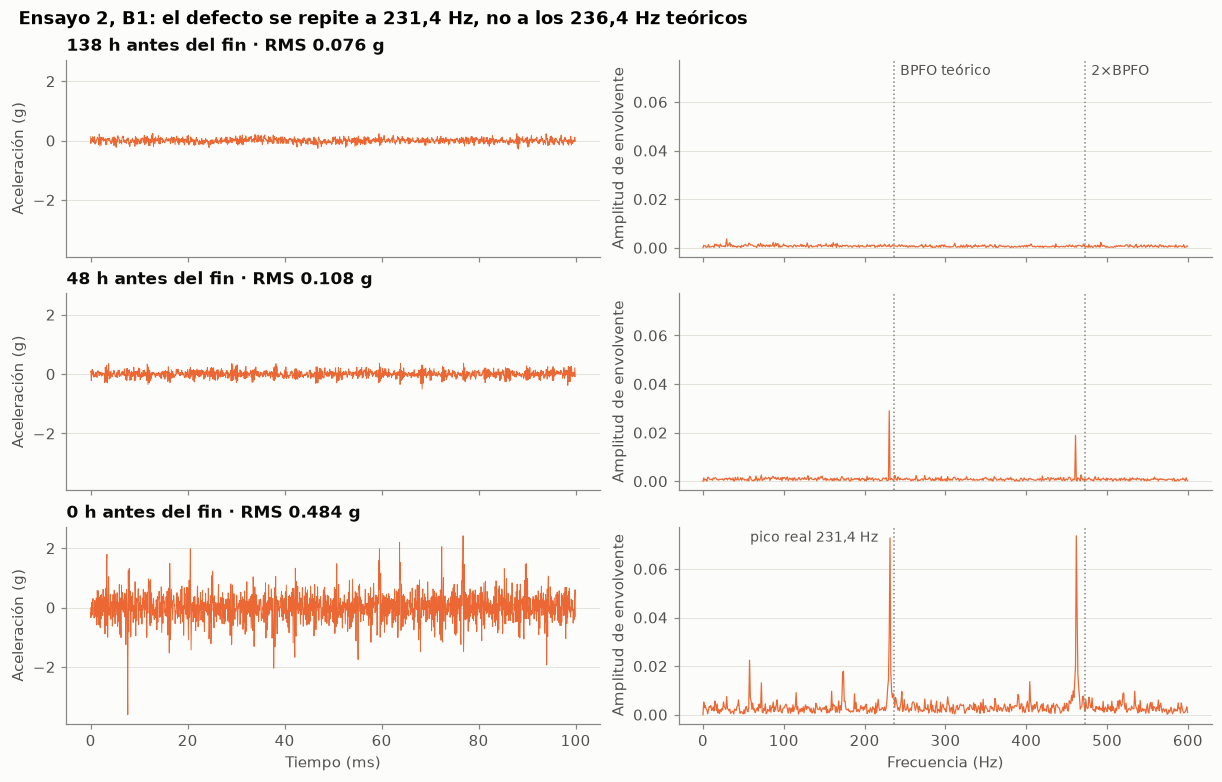

In [9]:
SOS = signal.butter(4, [2000, 8000], btype="bandpass", fs=FS, output="sos")
df2 = datos[2]
mon = df2[df2["fase"] == "monitoreo"]
elegidos = [mon.index[0], (mon["horas_al_fin"] - 48).abs().idxmin(), mon.index[-1]]

fig, ejes = plt.subplots(3, 2, figsize=(11, 7), sharex="col", sharey="col", layout="constrained")
picos = []
for fila, i in enumerate(elegidos):
    ts = df2.loc[i, "Timestamp"]
    x = pd.read_csv(os.path.join(CARPETAS[2], ts.strftime("%Y.%m.%d.%H.%M.%S")), sep="\t", header=None)[0].to_numpy()
    x = x - x.mean()
    t = np.arange(2000) / FS
    ejes[fila, 0].plot(t * 1000, x[:2000], color=NARANJA, lw=0.6)
    ejes[fila, 0].set_ylabel("Aceleración (g)")
    env = np.abs(signal.hilbert(signal.sosfiltfilt(SOS, x)))
    esp = np.abs(np.fft.rfft(env - env.mean())) / len(env)
    fr = np.fft.rfftfreq(len(env), 1 / FS)
    m = fr <= 600
    ejes[fila, 1].plot(fr[m], esp[m], color=NARANJA, lw=0.8)
    for k in (1, 2):
        ejes[fila, 1].axvline(k * BPFO, color=TENUE, ls=":", lw=1)
    banda = (fr > 200) & (fr < 260)
    picos.append((fr[banda][esp[banda].argmax()], esp[banda].max(), fila))
    ejes[fila, 0].set_title(f"{df2.loc[i, 'horas_al_fin']:.0f} h antes del fin · RMS {df2.loc[i, 'B1_rms']:.3f} g",
                            loc="left")
techo = ejes[0, 1].get_ylim()[1]
ejes[0, 1].annotate("BPFO teórico", (BPFO, techo * 0.92), xytext=(4, 0),
                    textcoords="offset points", color=TINTA2, fontsize=9)
ejes[0, 1].annotate("2×BPFO", (2 * BPFO, techo * 0.92), xytext=(4, 0),
                    textcoords="offset points", color=TINTA2, fontsize=9)
f_pico, a_pico, fila_pico = max(picos, key=lambda p: p[1])
ejes[fila_pico, 1].annotate(f"pico real {f_pico:.1f} Hz".replace(".", ","), (f_pico, a_pico), xytext=(-8, 0),
                            textcoords="offset points", ha="right", va="center", color=TINTA2, fontsize=9)
ejes[2, 0].set_xlabel("Tiempo (ms)")
ejes[2, 1].set_xlabel("Frecuencia (Hz)")
for ax in ejes[:, 1]:
    ax.set_ylabel("Amplitud de envolvente")
fig.suptitle(f"Ensayo 2, B1: el defecto se repite a {f_pico:.1f} Hz, no a los 236,4 Hz teóricos".replace(".", ",", 1),
             x=0.01, ha="left", fontsize=12, fontweight="bold")
plt.show()

**Qué quiere decir.** 48 horas antes del fin, la señal a simple vista se ve casi igual que al inicio, pero el espectro
de envolvente ya muestra un pico claro: el defecto ya existe y golpea unas 231 veces por segundo. Un análisis más fino
detecta el daño días antes de que la vibración total aumente.

## 4. Evolución en el tiempo

RMS (dividido por su mediana en el baseline, escala logarítmica) y curtosis de cada rodamiento a lo largo de cada
ensayo. Mediana móvil de 1 h para quitar ruido. En gris, los rodamientos sanos; en color, los que fallan. La franja
gris es el baseline y los cortes en las líneas son huecos de registro.

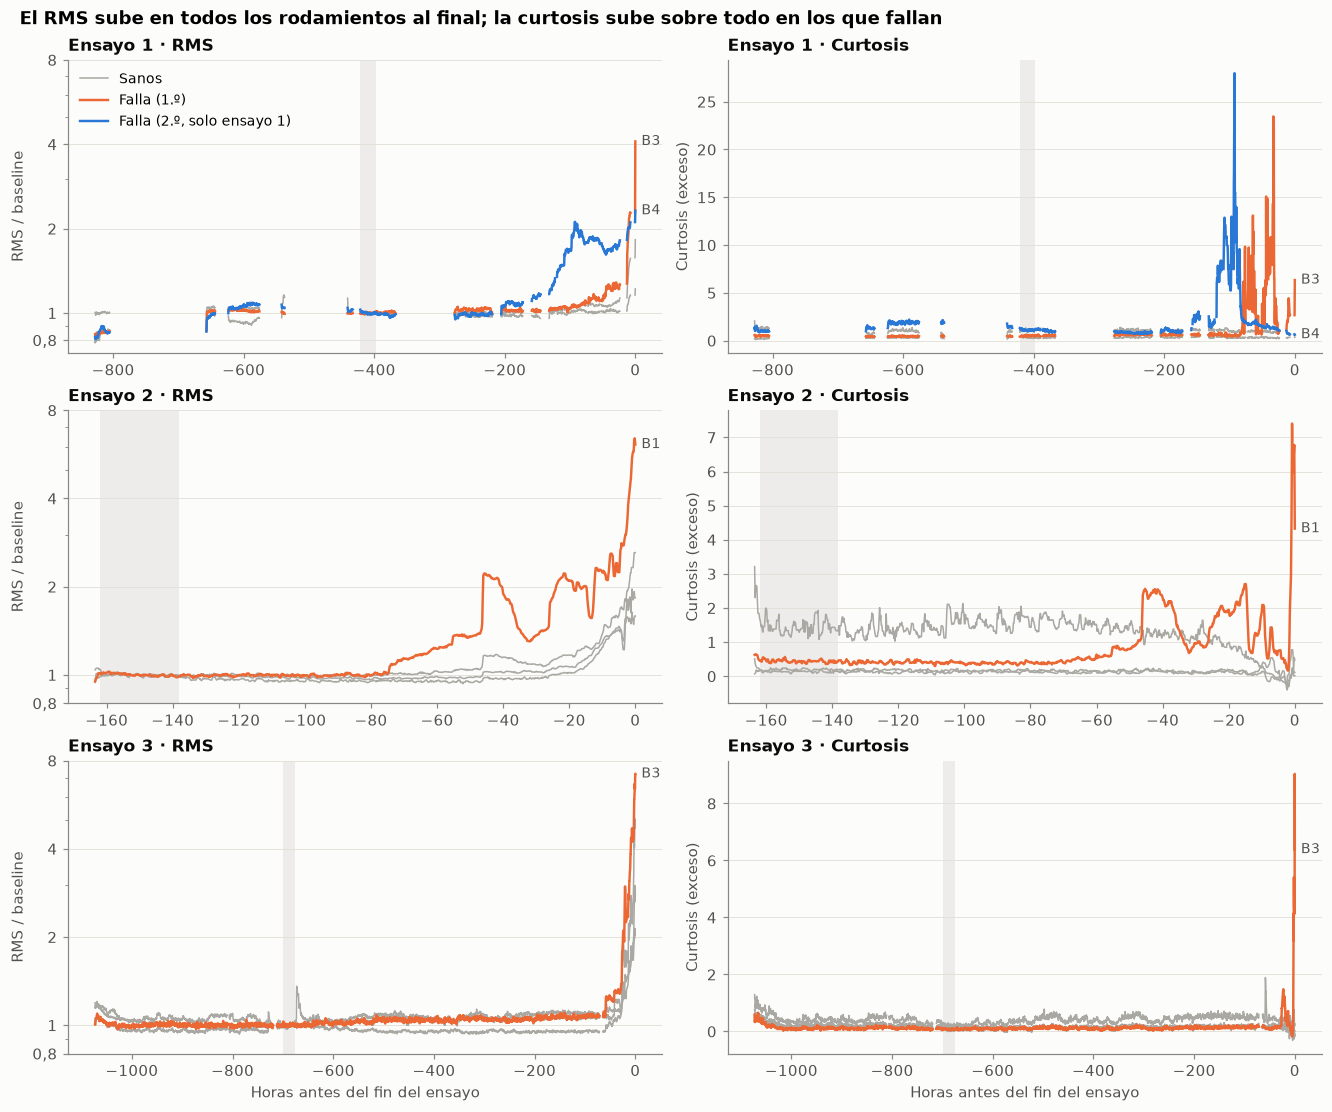

In [10]:
fig, ejes = plt.subplots(3, 2, figsize=(12, 10), layout="constrained")
for fila, (e, df) in enumerate(datos.items()):
    base = df["fase"] == "base"
    for col, f in enumerate(["rms", "kurt"]):
        ax = ejes[fila, col]
        for b in sorted(RODS, key=lambda r: r in FALLAN[e]):  # los que fallan se dibujan encima
            s = df[f"{b}_{f}"]
            if f == "rms":
                s = s / s[base].median()
            s = s.rolling(6, min_periods=1).median()
            x, y = con_cortes(df, s)
            falla = b in FALLAN[e]
            ax.plot(x, y, color=color_rod(e, b), lw=1.6 if falla else 1.0, zorder=3 if falla else 2)
            if falla:
                ax.annotate(b, (x[-1], y[-1]), xytext=(4, 0), textcoords="offset points",
                            color=TINTA2, fontsize=9, va="center")
        xb = -df.loc[base, "horas_al_fin"]
        ax.axvspan(xb.min(), xb.max(), color=GRIS, alpha=0.18, lw=0)
        if f == "rms":
            ax.set_yscale("log")
            ax.set_yticks([0.8, 1, 2, 4, 8]); ax.set_yticklabels(["0,8", "1", "2", "4", "8"])
            ax.yaxis.set_minor_formatter(plt.NullFormatter())
            ax.set_ylabel("RMS / baseline")
        else:
            ax.set_ylabel("Curtosis (exceso)")
        ax.set_title(f"Ensayo {e} · {'RMS' if f == 'rms' else 'Curtosis'}", loc="left")
for ax in ejes[2]:
    ax.set_xlabel("Horas antes del fin del ensayo")
ejes[0, 0].legend(handles=[Line2D([], [], color=GRIS, lw=1, label="Sanos"),
                           Line2D([], [], color=NARANJA, lw=1.6, label="Falla (1.º)"),
                           Line2D([], [], color=AZUL, lw=1.6, label="Falla (2.º, solo ensayo 1)")],
                  loc="upper left", fontsize=9)
fig.suptitle("El RMS sube en todos los rodamientos al final; la curtosis sube sobre todo en los que fallan",
             x=0.01, ha="left", fontsize=12, fontweight="bold")
plt.show()

**Acople entre rodamientos.** Los 4 rodamientos comparten eje, así que la vibración de uno se transmite a los demás.
Correlación de Spearman media entre los 4 RMS de cada ensayo, en el baseline y en las últimas 48 h.

In [11]:
filas = []
for e, df in datos.items():
    cols = [f"{b}_rms" for b in RODS]
    fila = {"Ensayo": e}
    for nombre, mask in [("Baseline", df["fase"] == "base"), ("Últimas 48 h", df["horas_al_fin"] <= 48)]:
        c = df.loc[mask, cols].corr(method="spearman").to_numpy()
        fila[nombre] = c[np.triu_indices(4, 1)].mean()
    filas.append(fila)
pd.DataFrame(filas).set_index("Ensayo").round(2)

,Baseline,Últimas 48 h
Ensayo,,
1,0.36,0.68
2,0.29,0.81
3,0.23,0.95


**Qué quiere decir.** Al final de cada ensayo el RMS sube en todos los rodamientos, porque comparten el eje y la
vibración del dañado se transmite a los demás. La tabla de acople lo confirma: al final los 4 rodamientos vibran casi
al unísono. Por eso una alarma sobre el RMS también suena en rodamientos sanos. La curtosis, en cambio, sube sobre todo
en los que fallan; en B4 del ensayo 1 sube y luego baja, porque cuando el daño se extiende los golpes dejan de ser
aislados.

## 5. Relaciones entre indicadores

Correlación de Spearman entre los 13 indicadores en el baseline (calculada por rodamiento y promediada sobre los 12,
para no mezclar diferencias de nivel entre rodamientos). Valores cercanos a ±1 indican indicadores redundantes.

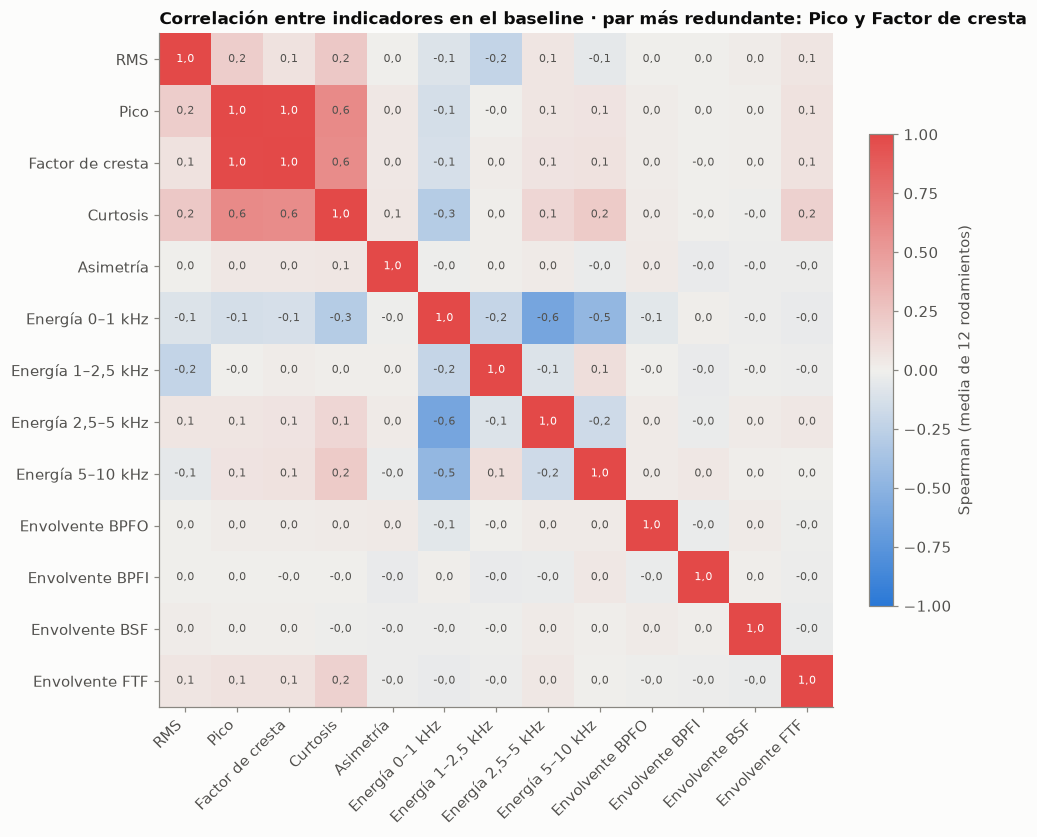

In [12]:
mats = []
for e, df in datos.items():
    base = df["fase"] == "base"
    for b in RODS:
        mats.append(df.loc[base, [f"{b}_{f}" for f in FEATS]].corr(method="spearman").to_numpy())
corr = pd.DataFrame(np.mean(mats, axis=0), index=[NOMBRES[f] for f in FEATS], columns=[NOMBRES[f] for f in FEATS])

cmap = LinearSegmentedColormap.from_list("div", [AZUL, "#f0efec", ROJO])
fig, ax = plt.subplots(figsize=(9, 7.5), layout="constrained")
im = ax.imshow(corr, cmap=cmap, vmin=-1, vmax=1)
ax.set_xticks(range(len(FEATS)), corr.columns, rotation=45, ha="right")
ax.set_yticks(range(len(FEATS)), corr.index)
ax.grid(False)
for i in range(len(FEATS)):
    for j in range(len(FEATS)):
        v = corr.iat[i, j]
        ax.text(j, i, f"{v:.1f}".replace(".", ","), ha="center", va="center", fontsize=7,
                color="white" if abs(v) > 0.65 else TINTA2)
fig.colorbar(im, ax=ax, shrink=0.7, label="Spearman (media de 12 rodamientos)")
par = corr.where(~np.eye(len(FEATS), dtype=bool)).abs().stack().idxmax()
ax.set_title(f"Correlación entre indicadores en el baseline · par más redundante: {par[0]} y {par[1]}", loc="left")
plt.show()

**Qué quiere decir.** Dos indicadores con correlación cercana a 1 dan la misma información, así que usar ambos no
agrega nada. Pico y factor de cresta son casi lo mismo en estado sano; basta con uno.

## 6. Supuestos de las cartas de control en el baseline

Las cartas Shewhart (I-MR, X̄-R, X̄-S) suponen que, en estado sano, los puntos son **independientes** y
**aproximadamente normales**, y que el proceso está **estable** (sin tendencia). Revisamos RMS y curtosis en las 24 h
de baseline de cada rodamiento (144 puntos):

- **Autocorrelación a 10 min (lag 1):** cerca de 0 = independientes.
- **Shapiro-Wilk:** p < 0,05 = se rechaza normalidad.
- **Tendencia:** pendiente del ajuste lineal, en % del nivel por día.
- **sd / σ_MR:** desviación estándar real dividida por la σ que usa la I-MR (MR̄/1,128); > 1 = la carta subestima la
  variabilidad.

In [13]:
filas = []
for e, df in datos.items():
    base = df["fase"] == "base"
    for b in RODS:
        fila = {"Ensayo": e, "Rod.": b + (" (falla)" if b in FALLAN[e] else "")}
        for f in ["rms", "kurt"]:
            s = df.loc[base, f"{b}_{f}"].reset_index(drop=True)
            horas = -df.loc[base, "horas_al_fin"].to_numpy()
            pend = np.polyfit(horas / 24, s, 1)[0]
            fila[f"{NOMBRES[f]}: autocorr."] = s.autocorr(1)
            fila[f"{NOMBRES[f]}: Shapiro p"] = stats.shapiro(s).pvalue
            if f == "rms":
                fila["RMS: tendencia (%/día)"] = 100 * pend / s.mean()
            fila[f"{NOMBRES[f]}: sd/σ_MR"] = s.std() / (s.diff().abs().mean() / 1.128)
        filas.append(fila)
supuestos = pd.DataFrame(filas).set_index(["Ensayo", "Rod."])
supuestos.round(3)

RMS: autocorr.  RMS: Shapiro p  RMS: tendencia (%/día)  RMS: sd/σ_MR  Curtosis: autocorr.  Curtosis: Shapiro p  Curtosis: sd/σ_MR
Ensayo Rod.                                                                                                                                         
1      B1                   0.314           0.174                  -1.403         1.205               -0.023                0.181              0.972
       B2                   0.205           0.649                  -0.819         1.111                0.039                0.011              1.064
       B3 (falla)           0.117           0.685                   0.717         1.048                0.016                0.000              1.133
       B4 (falla)           0.222           0.746                  -1.195         1.148               -0.282                0.034              0.856
2      B1 (falla)           0.298           0.634                  -2.754         1.221               -0.109                0.141              0.957
       B2                  -0.075           0.979                   0.006         0.940               -0.072                0.002              0.968
       B3                   0.309           0.715                  -3.174         1.234               -0.147                0.000              1.007
       B4                  -0.001           0.987                  -0.534         0.992               -0.073                0.018              0.982
3      B1                   0.187           0.919                   0.520         1.097               -0.148                0.250              0.901
       B2                  -0.095           0.341                   0.651         0.914                0.092                0.177              1.043
       B3 (falla)           0.065           0.004                   0.261         1.026               -0.042                0.137              0.986
       B4                   0.680           0.194                   4.888         1.848               -0.187                0.539              0.900

In [14]:
resumen = pd.Series({
    "Autocorrelación media del RMS": supuestos["RMS: autocorr."].mean(),
    "Autocorrelación media de la curtosis": supuestos["Curtosis: autocorr."].mean(),
    "Rodamientos con RMS no normal (p < 0,05)": int((supuestos["RMS: Shapiro p"] < 0.05).sum()),
    "Rodamientos con curtosis no normal (p < 0,05)": int((supuestos["Curtosis: Shapiro p"] < 0.05).sum()),
    "Tendencia del RMS, rango (%/día)": f"{supuestos['RMS: tendencia (%/día)'].min():.1f} a "
                                        f"{supuestos['RMS: tendencia (%/día)'].max():.1f}",
})
resumen

Autocorrelación media del RMS                      0.185442
Autocorrelación media de la curtosis              -0.078012
Rodamientos con RMS no normal (p < 0,05)                  1
Rodamientos con curtosis no normal (p < 0,05)             6
Tendencia del RMS, rango (%/día)                 -3.2 a 4.9
dtype: object

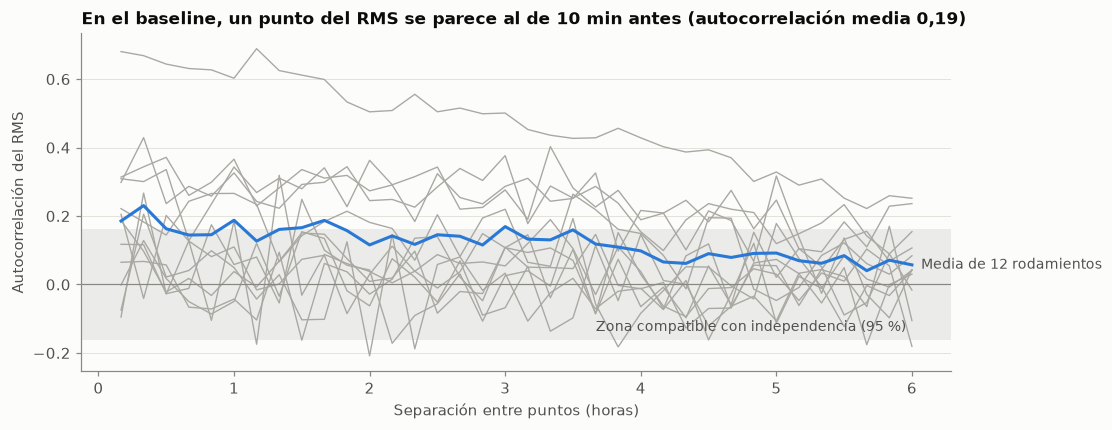

In [15]:
fig, ax = plt.subplots(figsize=(10, 3.8), layout="constrained")
lags = np.arange(1, 37)
acfs = []
for e, df in datos.items():
    base = df["fase"] == "base"
    for b in RODS:
        s = df.loc[base, f"{b}_rms"].reset_index(drop=True)
        acf = [s.autocorr(k) for k in lags]
        acfs.append(acf)
        ax.plot(lags * 10 / 60, acf, color=GRIS, lw=0.9)
media = np.mean(acfs, axis=0)
ax.plot(lags * 10 / 60, media, color=AZUL, lw=2)
ax.annotate("Media de 12 rodamientos", (lags[-1] * 10 / 60, media[-1]), xytext=(6, 0),
            textcoords="offset points", color=TINTA2, va="center", fontsize=9)
banda = 1.96 / np.sqrt(144)
ax.axhspan(-banda, banda, color=GRIS, alpha=0.2, lw=0)
ax.annotate("Zona compatible con independencia (95 %)", (6, -banda), xytext=(-4, 4), textcoords="offset points",
            ha="right", va="bottom", color=TINTA2, fontsize=9)
ax.axhline(0, color=TENUE, lw=0.8)
ax.set_xlabel("Separación entre puntos (horas)")
ax.set_ylabel("Autocorrelación del RMS")
ax.set_title(f"En el baseline, un punto del RMS se parece al de 10 min antes (autocorrelación media {media[0]:.2f})"
             .replace(".", ","), loc="left")
plt.show()

**Qué quiere decir.** Las cartas de control suponen que cada punto es independiente del anterior y que la señal no
tiene tendencia. El RMS no cumple ninguna de las dos: cada punto se parece al de 10 minutos antes y la señal sube o
baja lentamente incluso en el periodo sano. Por eso la carta I-MR sobre el RMS da tantas falsas alarmas. La curtosis sí
es independiente, aunque en la mitad de los rodamientos no tiene forma de campana.

## 7. Valores atípicos

Puntos fuera de las vallas de Tukey (Q1 − 1,5·RIC, Q3 + 1,5·RIC) del baseline, contados en el baseline y en el
monitoreo. Siguiendo el criterio del curso, **no se eliminan**: en monitoreo un atípico puede ser justamente el
inicio de la falla.

In [16]:
filas = []
for f in ["rms", "pico", "cresta", "kurt", "env_BPFO", "env_BPFI"]:
    fila = {"Indicador": NOMBRES[f]}
    for grupo in ["fallan", "sanos"]:
        for fase in ["base", "monitoreo"]:
            tasas = []
            for e, df in datos.items():
                for b in RODS:
                    if (b in FALLAN[e]) != (grupo == "fallan"):
                        continue
                    s = df[f"{b}_{f}"]
                    q1, q3 = s[df["fase"] == "base"].quantile([0.25, 0.75])
                    r = q3 - q1
                    x = s[df["fase"] == fase]
                    tasas.append(100 * ((x < q1 - 1.5 * r) | (x > q3 + 1.5 * r)).mean())
            fila[f"{grupo.capitalize()} · {fase} (%)"] = np.mean(tasas)
    filas.append(fila)
pd.DataFrame(filas).set_index("Indicador").round(1)

,Fallan · base (%),Fallan · monitoreo (%),Sanos · base (%),Sanos · monitoreo (%)
Indicador,,,,
RMS,0.2,58.3,0.5,45.8
Pico,2.8,37.5,1.8,7.2
Factor de cresta,3.3,18.1,1.8,2.8
Curtosis,1.7,34.3,1.2,10.9
Envolvente BPFO,2.1,20.8,2.3,11.8
Envolvente BPFI,1.7,13.3,1.7,2.2


**Qué quiere decir.** En el periodo sano casi no hay valores atípicos. En el monitoreo, la curtosis de los rodamientos
que fallan sale de lo normal mucho más seguido que en los sanos: los atípicos son justamente la señal de la falla, por
eso no se borran.

## 8. Conclusiones del EDA

**Calidad de los datos**
- No hay valores faltantes, timestamps duplicados ni valores imposibles. Todos los archivos tienen 20 480 muestras.
- **3 archivos con señal muerta** al final (2 en el ensayo 2, 1 en el ensayo 3): la máquina ya estaba detenida.
  Ya se excluyen en todo el análisis; al repetir las fases 2 a 6 sin ellos, J cambió como máximo 0,002.
- El ensayo 1 tiene 24 huecos: solo 341 de sus 828 h tienen registro, y el primer tramo se tomó cada 5 min.

**Qué cambia antes de la falla**
- El RMS es el que más cambia, pero también sube en los sanos (36σ al final), porque los 4 rodamientos comparten
  eje: la correlación entre ellos pasa de 0,23–0,36 en el baseline a 0,68–0,95 en las últimas 48 h.
- La **curtosis es el indicador más selectivo**: +11σ en los que fallan y ~0 en los sanos. El pico y la energía de
  2,5–5 kHz también separan.
- La **envolvente en BPFO** es el segundo indicador que más separa (+32σ en los que fallan, +9σ en los sanos),
  después de corregir un error: la falla del ensayo 2 se repite a ~231 Hz y no a los 236,4 Hz teóricos, y la
  primera versión buscaba solo en ±3 Hz. Ahora busca en ±5 %. Que también suba en los sanos puede deberse al eje
  compartido o a que la ventana incluye el 7.º armónico del eje (233 Hz); hay que revisarlo.
- La envolvente en BPFI separa poco porque solo 1 de los 4 rodamientos que fallan (ensayo 1, B3) tiene falla en
  la pista interna; el indicador es específico del tipo de falla.

**Redundancias**
- Pico y factor de cresta son el mismo indicador en el baseline (ρ = 1,0), porque el RMS casi no varía; basta uno.
- En el ensayo 1 los dos canales coinciden en RMS (ρ 0,80–0,96) pero no en curtosis ni pico (0,15–0,78).
  Promediarlos diluye justo los indicadores de golpes; conviene usar cada canal o el máximo de los dos.

**Supuestos de las cartas de control**
- RMS: es aproximadamente normal (11 de 12 rodamientos), pero **no es independiente** (autocorrelación media 0,19,
  hasta 0,68) y **tiene tendencia** incluso dentro de las 24 h de baseline (−3,2 a +4,9 % por día). Por eso la σ de la
  I-MR lo subestima hasta 1,8 veces y salen falsas alarmas.
- Curtosis: es independiente (autocorrelación ~0), pero **no es normal** en 6 de 12 rodamientos (sesgada a la
  derecha). Los límites de ±3σ no dan el 0,27 % de falsas alarmas esperado; conviene una transformación (log) o
  límites por percentiles.
- Los atípicos no se eliminan: en monitoreo son la señal. La curtosis queda fuera de las vallas de Tukey el 34 % del
  tiempo en los que fallan y el 11 % en los sanos.

**Siguientes pasos que salen de este EDA**
1. Llevar la envolvente BPFO a las cartas de control, junto al RMS y la curtosis.
2. Probar la curtosis por canal (o el máximo) en el ensayo 1.
3. Para el RMS, probar una carta sobre residuos o un RMS relativo (rodamiento frente al promedio de los otros
   tres) para quitar la deriva y el efecto del eje compartido.